In [86]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline 
sns.set(color_codes=True)
from scipy.stats import poisson


In [2]:
df = pd.read_csv("20260327_Notas_y_Egresados_Enseñanza_Media_2025_PUBL.csv")

In [3]:
df.shape

(290825, 21)

In [4]:
df.head()

,AGNO,RBD,DGV_RBD,COD_REG_RBD,NOM_REG_RBD_A,COD_PRO_RBD,COD_COM_RBD,NOM_COM_RBD,COD_DEPROV_RBD,NOM_DEPROV_RBD,...,COD_GRADO,COD_DEPE,COD_DEPE2,RURAL_RBD,MRUN,MRUN_IPE,PROM_NOTAS_ALU,ORIGEN,ENSE_COMPLETA,MARCA_EGRESO
0,2025,2308,6.0,6.0,LGBO,61.0,6115.0,RENGO,61.0,CACHAPOAL,...,4,3.0,2.0,0.0,89,NaN,61.0,SIGE,1,1
1,2025,17810,1.0,8.0,BBIO,82.0,8203.0,CAÑETE,84.0,ARAUCO,...,4,3.0,2.0,0.0,129,NaN,60.0,SIGE,1,1
2,2025,12305,6.0,5.0,VALPO,58.0,5804.0,VILLA ALEMANA,53.0,VALPARAÍSO,...,4,3.0,2.0,0.0,258,NaN,53.0,SIGE,1,1
3,2025,8005,5.0,10.0,LAGOS,102.0,10201.0,CASTRO,102.0,CHILOÉ,...,4,6.0,5.0,0.0,259,NaN,57.0,SIGE,1,1
4,2025,60,4.0,15.0,AYP,151.0,15101.0,ARICA,151.0,ARICA,...,4,3.0,2.0,0.0,326,NaN,63.0,SIGE,1,1


In [5]:
df.describe()

,AGNO,RBD,DGV_RBD,COD_REG_RBD,COD_PRO_RBD,COD_COM_RBD,COD_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE,COD_DEPE2,RURAL_RBD,MRUN,MRUN_IPE,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
count,290825.0,290825.000000,281940.000000,281939.000000,281939.000000,281939.000000,281939.000000,290825.000000,290825.000000,281939.000000,281939.000000,281939.000000,2.908250e+05,1.507500e+04,282186.000000,290825.0,290825.000000
mean,2025.0,12049.609280,4.457062,9.375209,95.691845,9575.524298,94.020579,376.690250,3.933066,3.246596,2.314089,0.033380,1.396640e+07,2.625776e+07,59.951475,1.0,0.967441
std,0.0,9566.592907,2.879106,4.010426,39.899787,3992.667939,39.258032,102.951697,0.390752,1.342484,1.249776,0.179626,8.171321e+06,1.821352e+06,6.168528,0.0,0.177480
min,2025.0,0.000000,0.000000,1.000000,11.000000,1101.000000,11.000000,310.000000,1.000000,1.000000,1.000000,0.000000,8.900000e+01,1.301430e+05,18.000000,1.0,0.000000
25%,2025.0,4277.000000,2.000000,6.000000,61.000000,6105.000000,61.000000,310.000000,4.000000,3.000000,2.000000,0.000000,6.948563e+06,2.560281e+07,56.000000,1.0,1.000000
50%,2025.0,9877.000000,4.000000,10.000000,101.000000,10101.000000,92.000000,310.000000,4.000000,3.000000,2.000000,0.000000,1.384935e+07,2.614468e+07,61.000000,1.0,1.000000
75%,2025.0,17833.000000,7.000000,13.000000,131.000000,13122.000000,133.000000,410.000000,4.000000,4.000000,3.000000,0.000000,2.080564e+07,2.719090e+07,65.000000,1.0,1.000000
max,2025.0,95850.000000,9.000000,16.000000,163.000000,16305.000000,151.000000,910.000000,4.000000,6.000000,5.000000,1.000000,2.848344e+07,2.848344e+07,70.000000,1.0,1.000000


In [6]:
Columns_Eliminate = ["COD_REG_RBD", "COD_PRO_RBD", "COD_COM_RBD","COD_DEPROV_RBD","COD_DEPE","ORIGEN","DGV_RBD","MRUN_IPE","AGNO"]
df = df.drop(columns=Columns_Eliminate)

In [7]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290825 entries, 0 to 290824
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   RBD             290825 non-null  int64  
 1   NOM_REG_RBD_A   281939 non-null  object 
 2   NOM_COM_RBD     281939 non-null  object 
 3   NOM_DEPROV_RBD  281939 non-null  object 
 4   COD_ENSE        290825 non-null  int64  
 5   COD_GRADO       290825 non-null  int64  
 6   COD_DEPE2       281939 non-null  float64
 7   RURAL_RBD       281939 non-null  float64
 8   MRUN            290825 non-null  int64  
 9   PROM_NOTAS_ALU  282186 non-null  float64
 10  ENSE_COMPLETA   290825 non-null  int64  
 11  MARCA_EGRESO    290825 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 26.6+ MB


In [8]:
Category_columns = { "COD_DEPE2": "category", "RURAL_RBD": "category", "ENSE_COMPLETA": "category", "MARCA_EGRESO": "category", "COD_ENSE": "category","COD_GRADO": "category"}
df = df.astype(Category_columns)

In [9]:
df

,RBD,NOM_REG_RBD_A,NOM_COM_RBD,NOM_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE2,RURAL_RBD,MRUN,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290820,0,NaN,NaN,NaN,310,4,NaN,NaN,28483437,NaN,1,1
290821,0,NaN,NaN,NaN,310,1,NaN,NaN,28483438,NaN,1,0
290822,0,NaN,NaN,NaN,310,2,NaN,NaN,28483438,NaN,1,0
290823,0,NaN,NaN,NaN,310,3,NaN,NaN,28483438,NaN,1,0


In [10]:
df.isnull().sum()

RBD                  0
NOM_REG_RBD_A     8886
NOM_COM_RBD       8886
NOM_DEPROV_RBD    8886
COD_ENSE             0
COD_GRADO            0
COD_DEPE2         8886
RURAL_RBD         8886
MRUN                 0
PROM_NOTAS_ALU    8639
ENSE_COMPLETA        0
MARCA_EGRESO         0
dtype: int64

In [11]:
dfc= df.dropna().copy()

In [12]:
dfc.isnull().sum()

RBD               0
NOM_REG_RBD_A     0
NOM_COM_RBD       0
NOM_DEPROV_RBD    0
COD_ENSE          0
COD_GRADO         0
COD_DEPE2         0
RURAL_RBD         0
MRUN              0
PROM_NOTAS_ALU    0
ENSE_COMPLETA     0
MARCA_EGRESO      0
dtype: int64

In [13]:
dfc

,RBD,NOM_REG_RBD_A,NOM_COM_RBD,NOM_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE2,RURAL_RBD,MRUN,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290537,20440,RM,RECOLETA,SANTIAGO NORTE,310,2,1.0,0.0,28483366,67.0,1,0
290538,20440,RM,RECOLETA,SANTIAGO NORTE,310,4,1.0,0.0,28483366,68.0,1,1
290587,578,COQ,LA SERENA,ELQUI,310,3,5.0,0.0,28483379,55.0,1,0
290588,578,COQ,LA SERENA,ELQUI,310,4,5.0,0.0,28483379,57.0,1,1


In [14]:
dfc = dfc.rename(columns={"RBD": "School ID", "NOM_REG_RBD_A": "Region","NOM_COM_RBD": "Municipality",  "NOM_DEPROV_RBD": "Provincial Department of Education ", "COD_ENSE": "Education level ", "COD_GRADO": "Grade level ","COD_DEPE2": "School dependency","RURAL_RBD": "School rurality","MRUN": "Student ID","PROM_NOTAS_ALU": "GPA","ENSE_COMPLETA": "Complete high school","MARCA_EGRESO": "Graduation status indicator"})

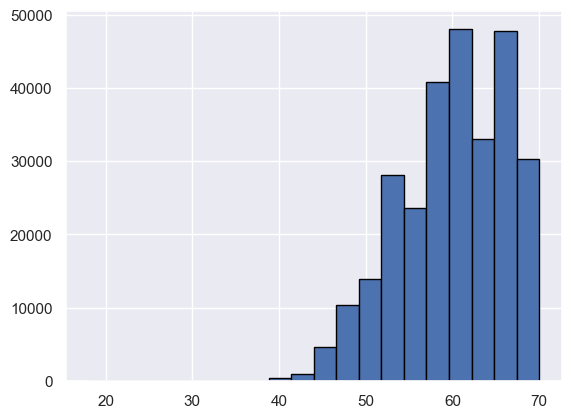

In [15]:
dfc['GPA'].hist(bins=20, edgecolor='black')
plt.show()

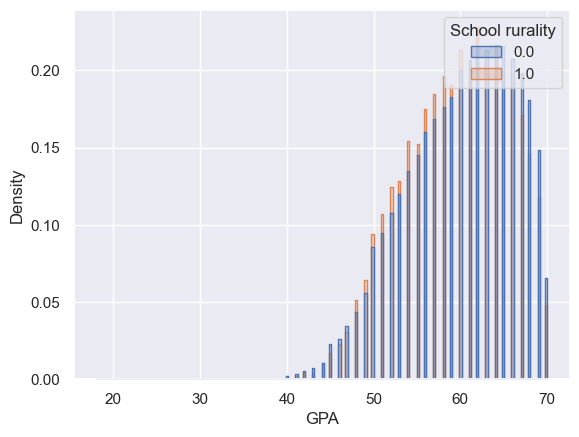

In [16]:
sns.histplot(data=dfc, x='GPA', hue="School rurality",stat="density",common_norm=False,element="step")
plt.show()

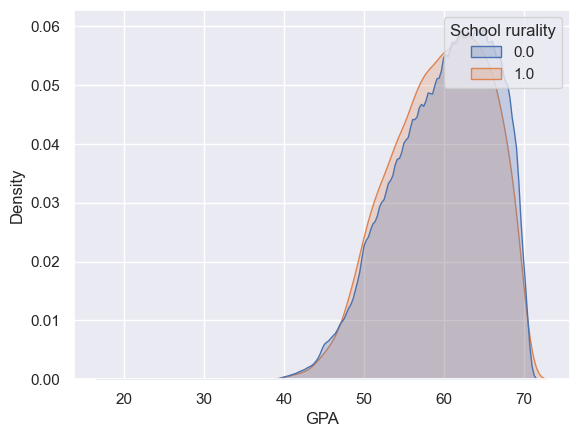

In [18]:
sns.kdeplot(data=dfc, x='GPA', hue="School rurality",common_norm=False, fill=True)
plt.show()

In [19]:
dfc

,School ID,Region,Municipality,Provincial Department of Education,Education level,Grade level,School dependency,School rurality,Student ID,GPA,Complete high school,Graduation status indicator
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290537,20440,RM,RECOLETA,SANTIAGO NORTE,310,2,1.0,0.0,28483366,67.0,1,0
290538,20440,RM,RECOLETA,SANTIAGO NORTE,310,4,1.0,0.0,28483366,68.0,1,1
290587,578,COQ,LA SERENA,ELQUI,310,3,5.0,0.0,28483379,55.0,1,0
290588,578,COQ,LA SERENA,ELQUI,310,4,5.0,0.0,28483379,57.0,1,1


In [20]:
Public = [1, 4, 5]
Private=[3]
conditions = [dfc['School dependency'].isin(Public), dfc['School dependency'].isin(Private)]
results = ['Public', 'Private']
dfc['School_dependency_Public_Private'] = np.select(conditions, results, default="State-funded private school")

In [21]:
dfc['GPA'] = dfc['GPA'].astype('float64')

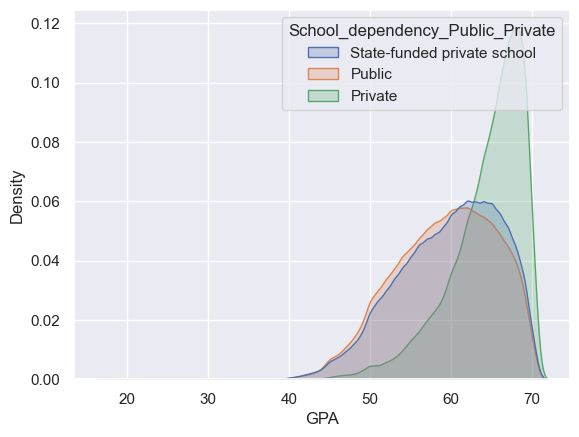

In [22]:
sns.kdeplot(data=dfc, x='GPA', hue='School_dependency_Public_Private',common_norm=False, fill=True)
plt.show()

In [23]:
Gpa = dfc.groupby('Region')['GPA'].agg(Promedio='mean',Desviacion_Estandar='std', Mediana='median',Moda=lambda x: x.mode()[0]).round(2).reset_index()
display(Gpa)

,Region,Promedio,Desviacion_Estandar,Mediana,Moda
0,ANTOF,59.94,5.87,61.0,60.0
1,ARAUC,59.33,6.05,60.0,61.0
2,ATCMA,58.79,6.61,59.0,60.0
3,AYP,60.64,6.15,62.0,66.0
4,AYSEN,59.48,6.14,60.0,65.0
5,BBIO,60.30,6.08,61.0,65.0
6,COQ,59.85,6.05,61.0,63.0
7,LAGOS,59.31,5.96,60.0,62.0
8,LGBO,59.49,6.47,60.0,62.0
9,MAG,60.86,5.71,62.0,62.0


In [51]:
Gpa = dfc.groupby('Municipality')['GPA'].agg(Promedio='mean',Desviacion_Estandar='std', Mediana='median',Moda=lambda x: x.mode()[0]).round(2).reset_index()
display(Gpa)

,Municipality,Promedio,Desviacion_Estandar,Mediana,Moda
0,ALGARROBO,62.06,5.14,63.0,64.0
1,ALHUÉ,60.59,6.65,62.0,63.0
2,ALTO BIOBÍO,58.10,5.57,59.0,59.0
3,ALTO DEL CARMEN,57.53,5.14,57.0,54.0
4,ALTO HOSPICIO,59.95,5.66,61.0,63.0
...,...,...,...,...,...
327,YUMBEL,60.80,5.55,62.0,65.0
328,YUNGAY,61.83,6.28,63.0,66.0
329,ZAPALLAR,59.80,6.62,61.0,64.0
330,ÑIQUÉN,61.86,5.58,63.0,58.0


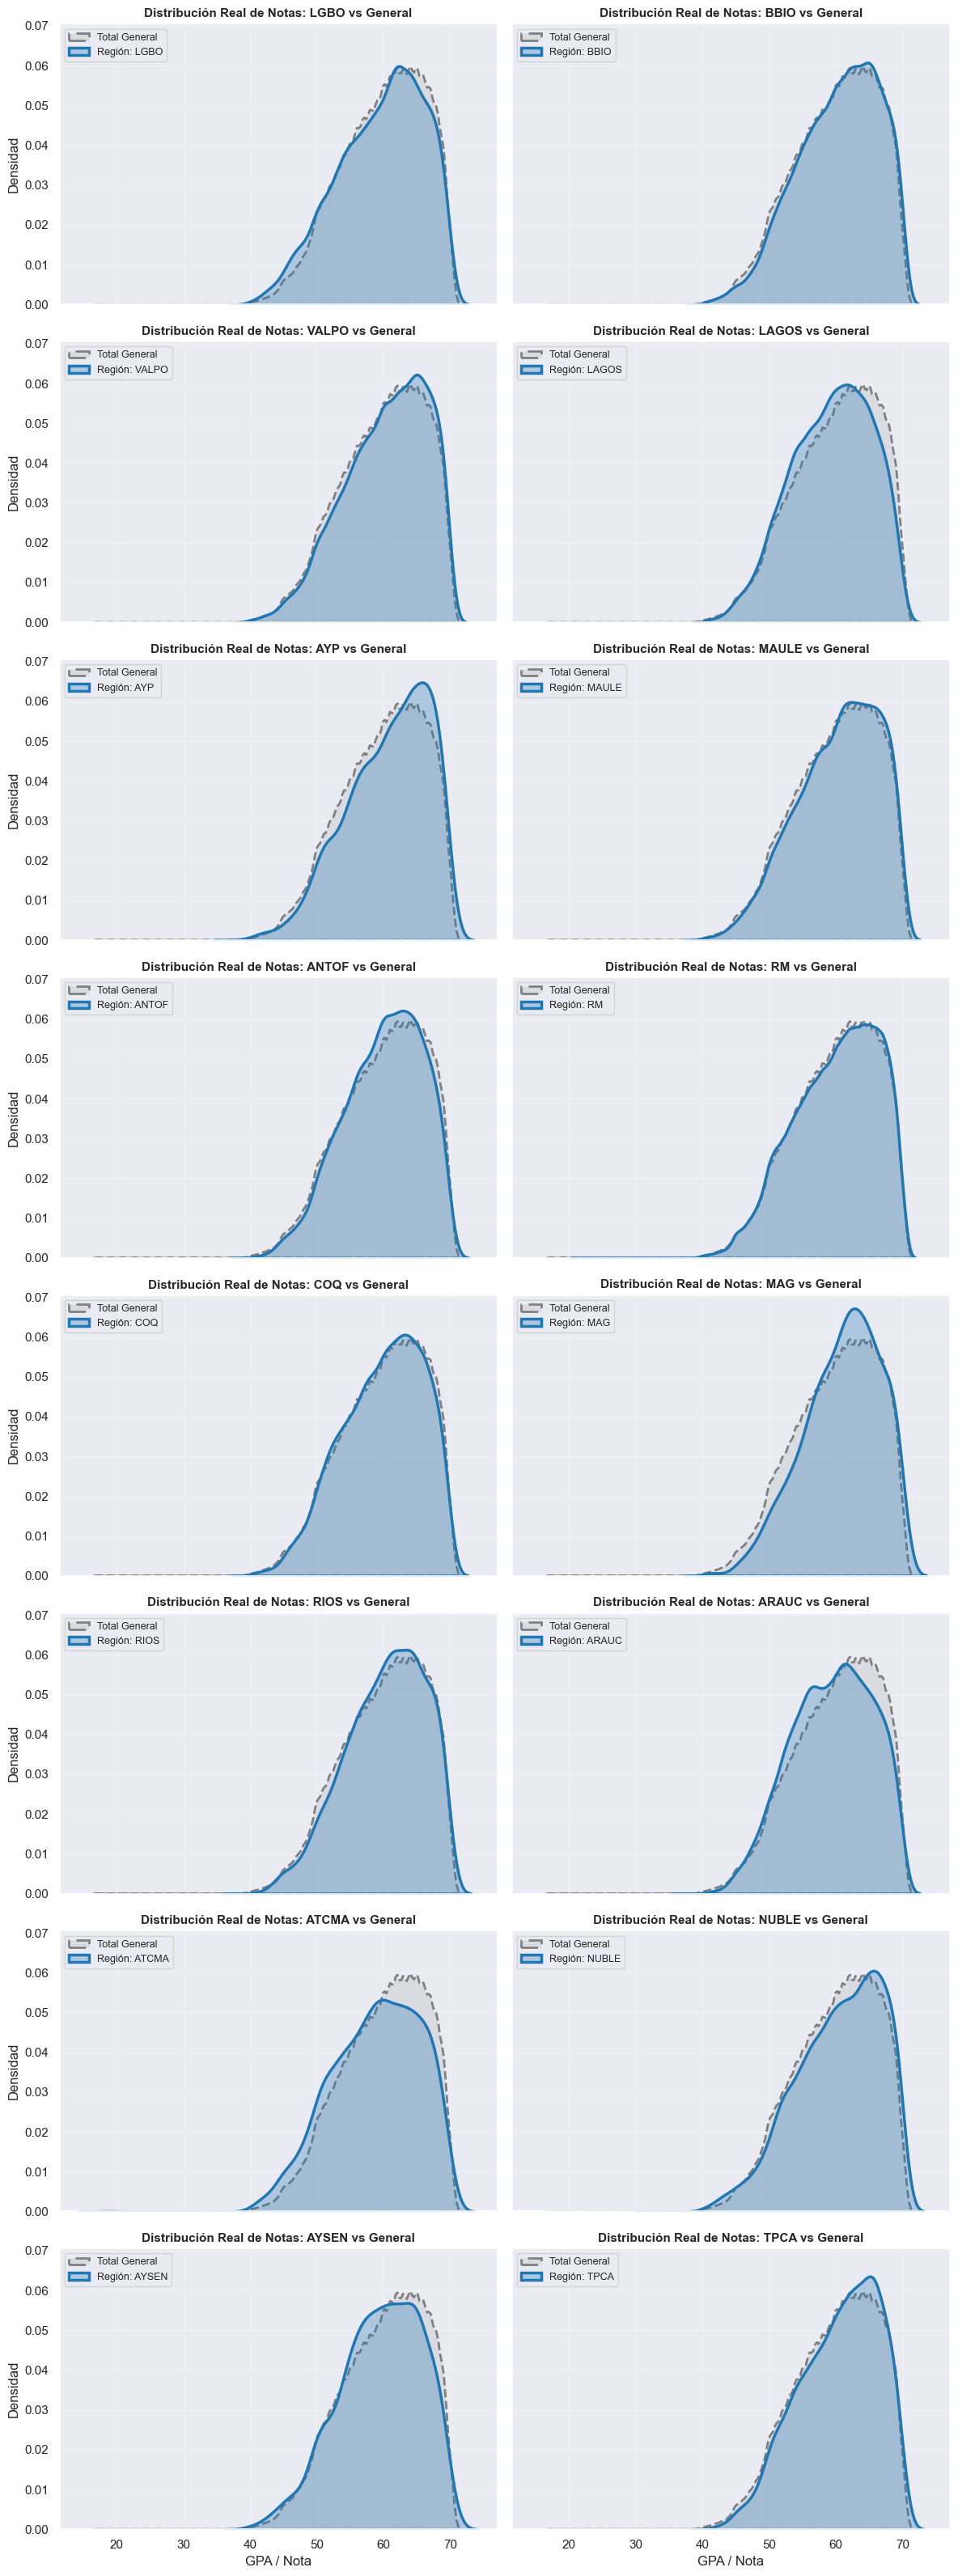

In [29]:
regiones = dfc['Region'].unique()
ncols = 2
nrows = math.ceil(len(regiones) / ncols)

# 2. Configurar la grilla de gráficos
fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(12, 4 * nrows),
    sharex=True,
    sharey=True,
)
axes = axes.flatten()

# 3. Graficar en cada recuadro la campana general y la campana regional
for i, reg in enumerate(regiones):
    ax = axes[i]

    # Campana del Total General (Todas las notas exactas)
    sns.kdeplot(
        data=dfc,
        x='GPA',
        ax=ax,
        color='gray',
        linestyle='--',
        linewidth=2,
        fill=True,
        alpha=0.15,
        label='Total General',
    )

    # Campana de la Región (Notas exactas de esa región)
    sns.kdeplot(
        data=dfc[dfc['Region'] == reg],
        x='GPA',
        ax=ax,
        color='tab:blue',
        linewidth=2.5,
        fill=True,
        alpha=0.3,
        label=f'Región: {reg}',
    )
    ax.set_xlabel('GPA / Nota')
    ax.set_ylabel('Densidad')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

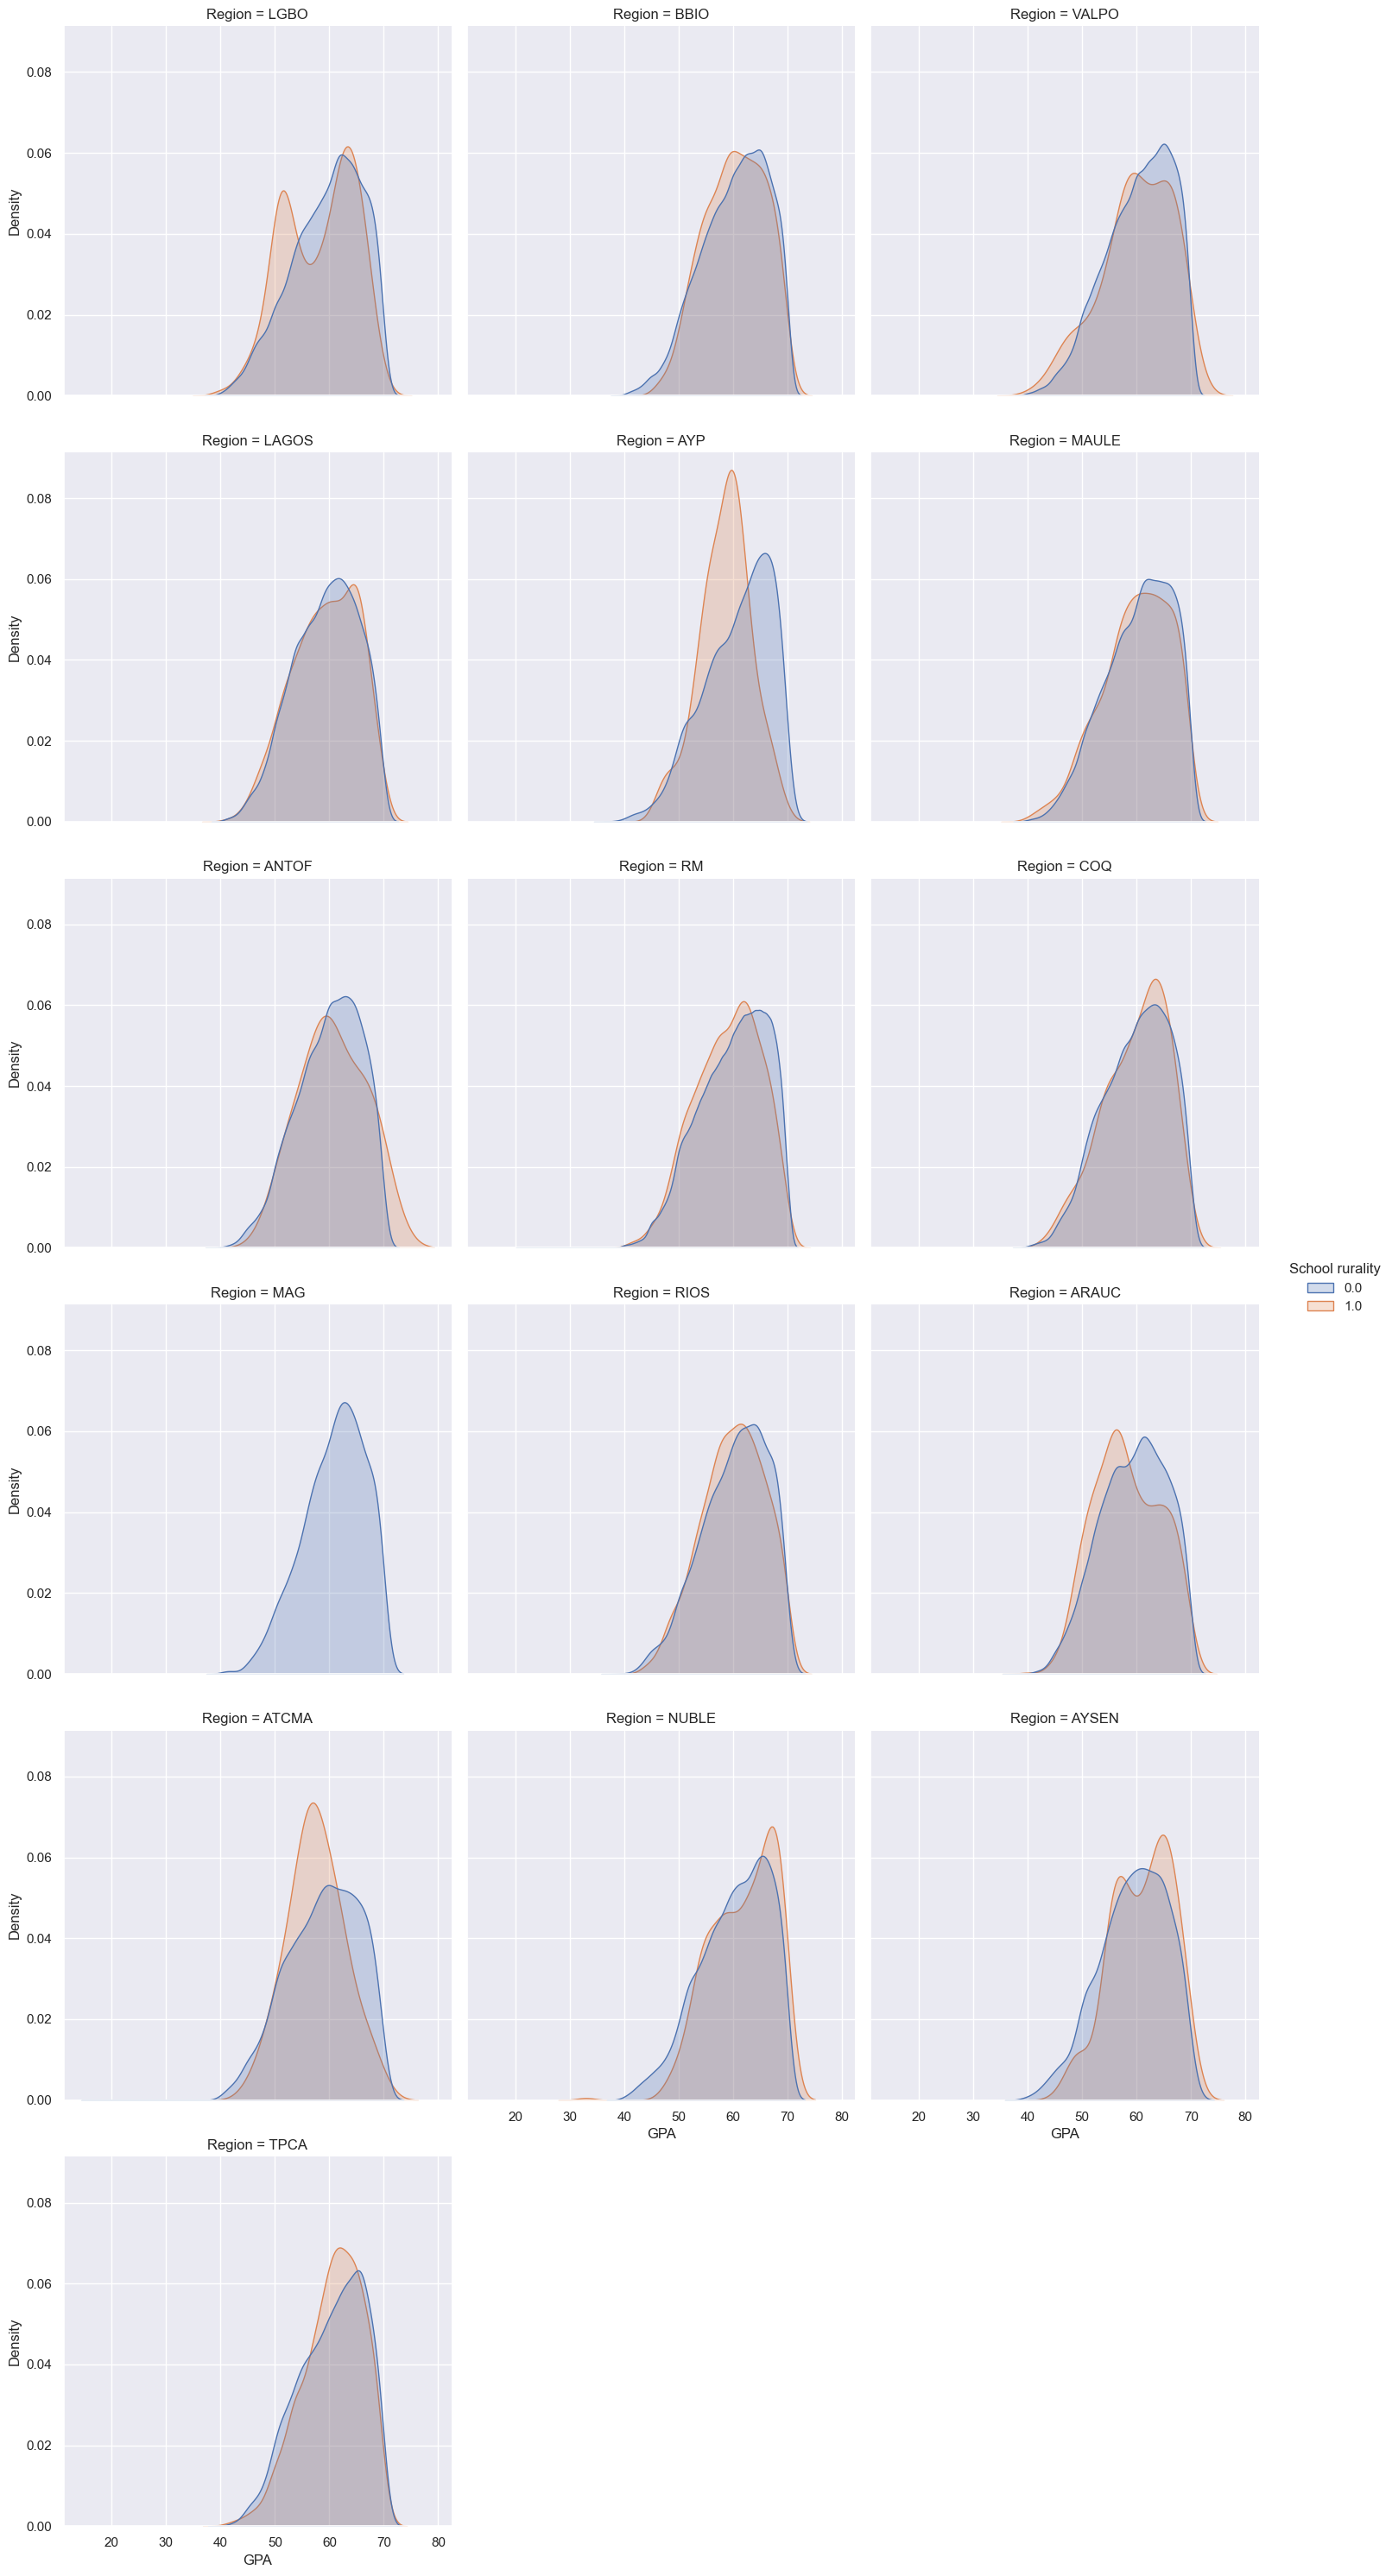

In [33]:
g = sns.displot(
    data=dfc,
    x='GPA',
    hue="School rurality",
    col='Region',          # Crea una columna por cada valor único de Region
    col_wrap=3,            # Opcional: número máximo de columnas por fila
    kind='kde',            # Especifica que es un gráfico KDE
    common_norm=False,
    fill=True
)

plt.show()

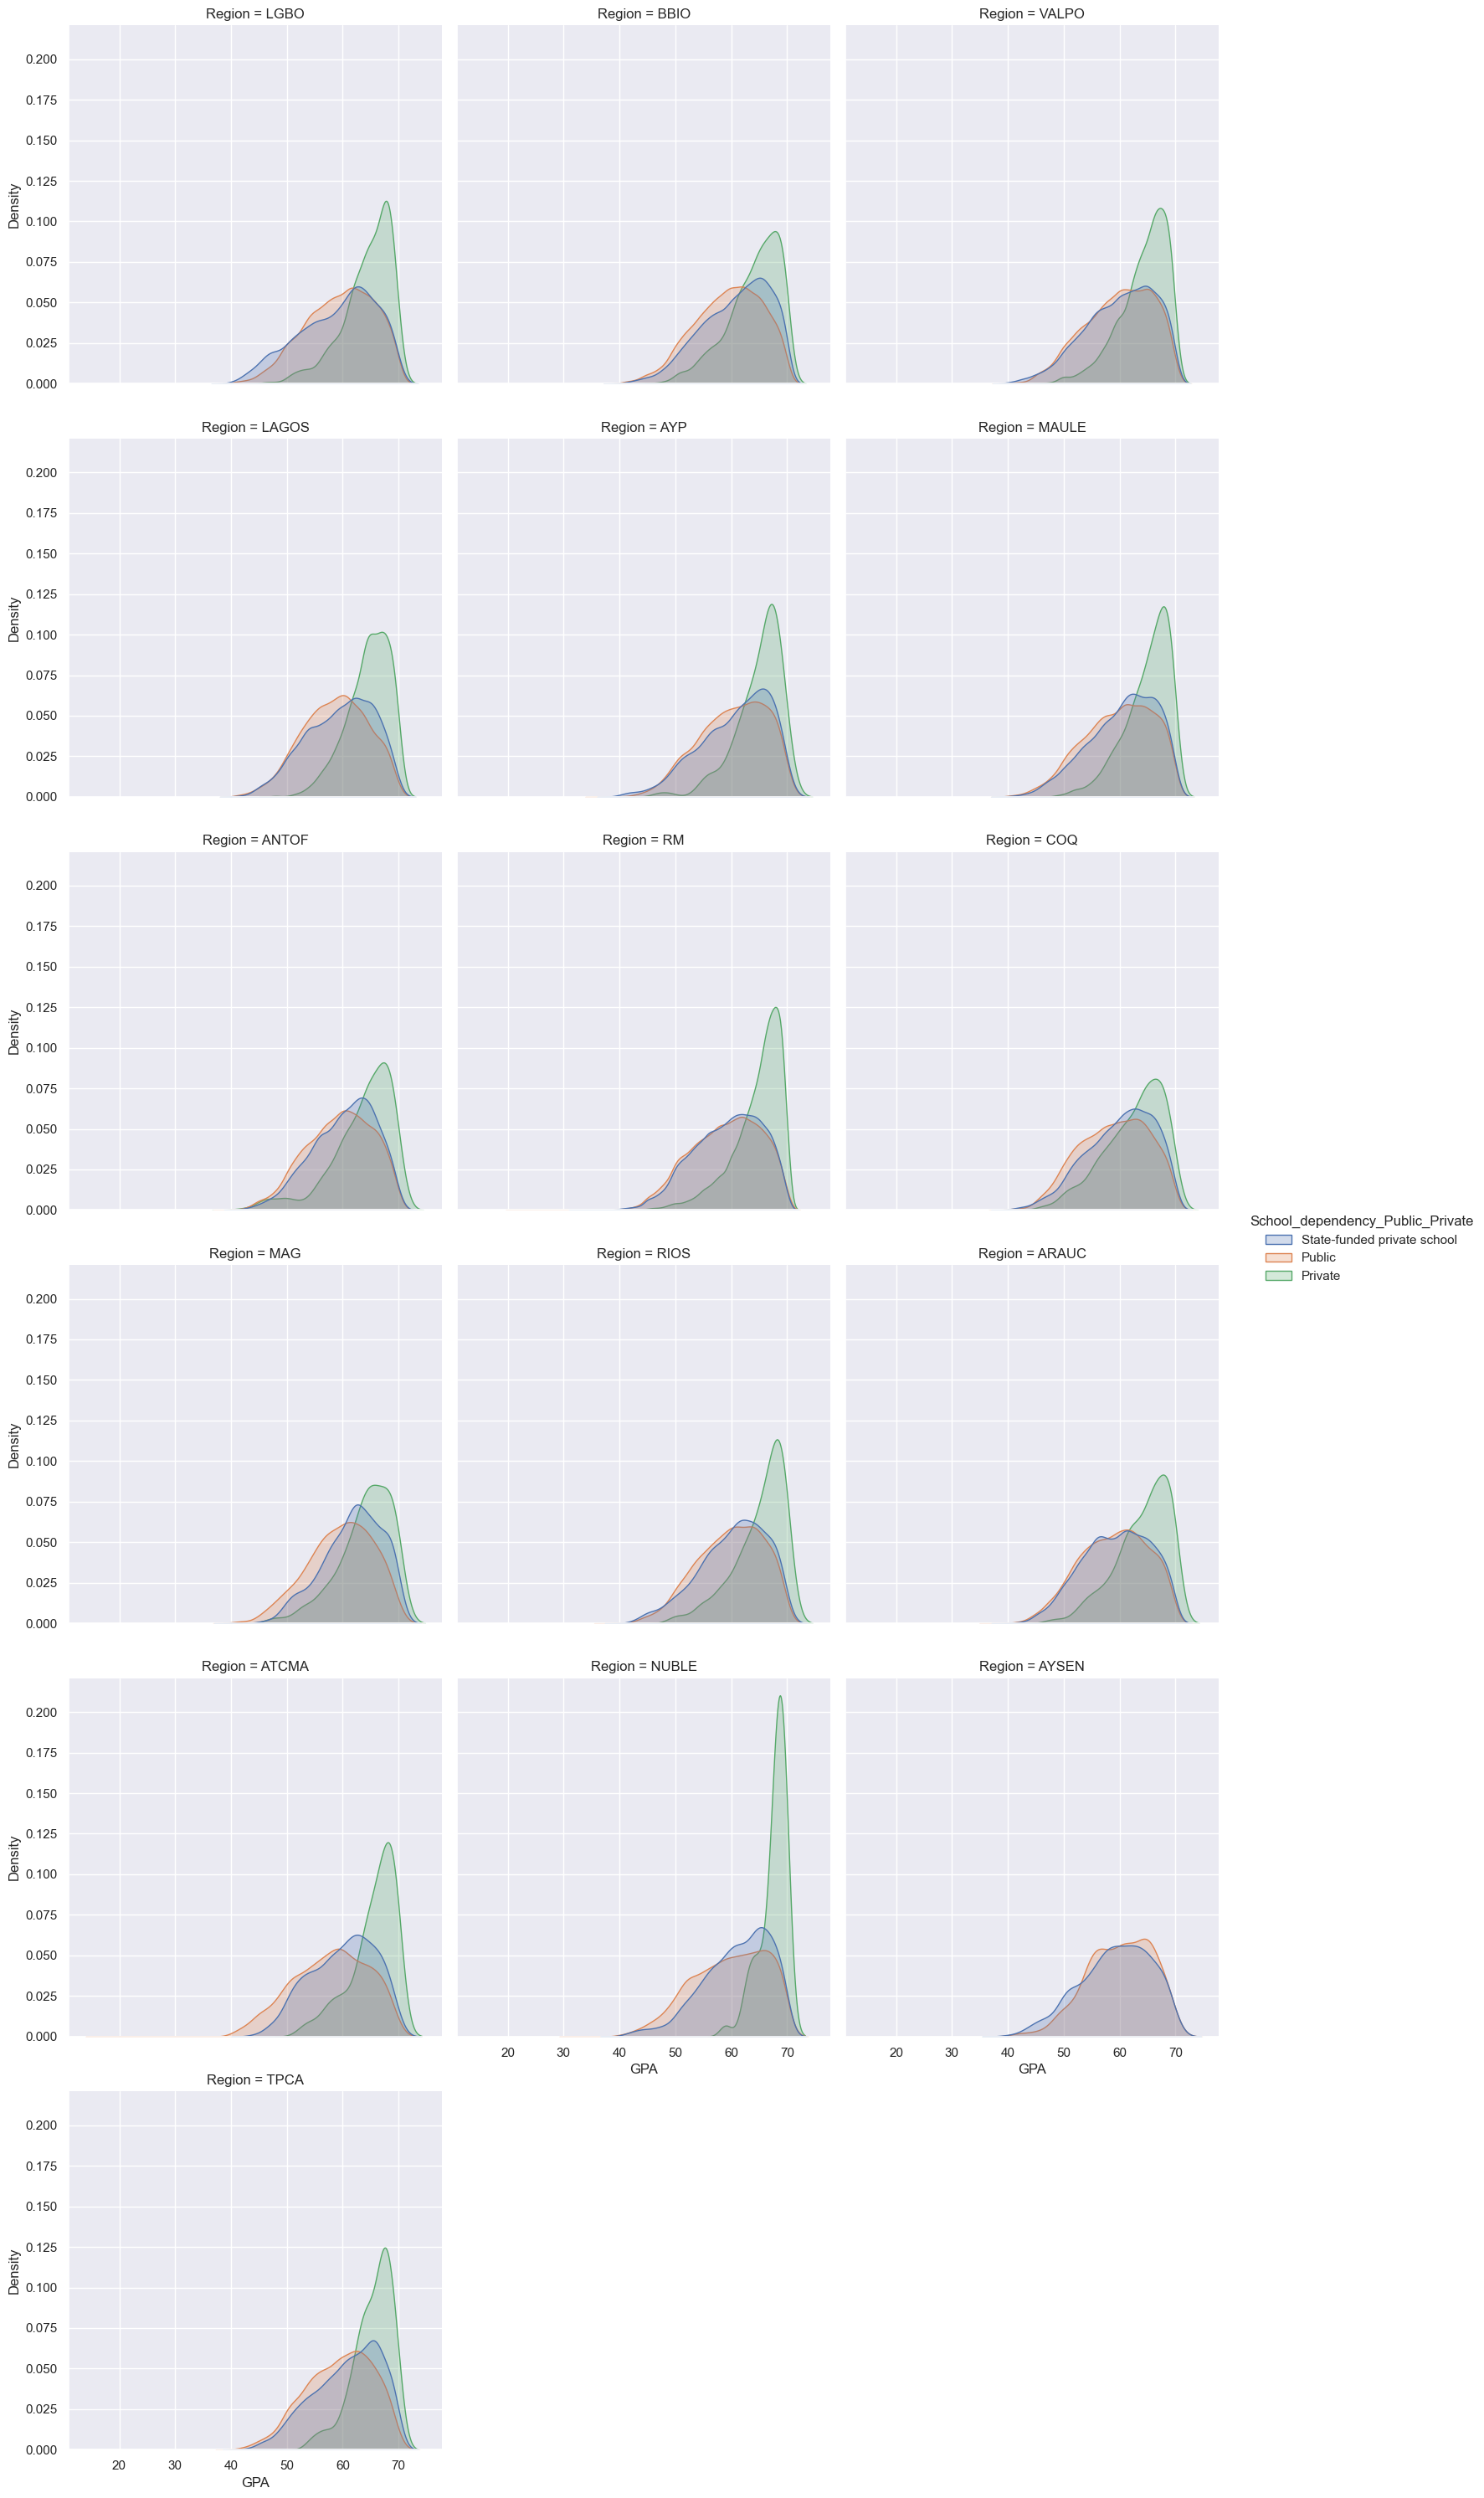

In [34]:
g = sns.displot(
    data=dfc,
    x='GPA',
    hue="School_dependency_Public_Private",
    col='Region',          # Crea una columna por cada valor único de Region
    col_wrap=3,            # Opcional: número máximo de columnas por fila
    kind='kde',            # Especifica que es un gráfico KDE
    common_norm=False,
    fill=True
)

plt.show()

In [57]:
import pandas as pd

# 1. Limpiar posibles espacios en los nombres de las columnas
dfc.columns = dfc.columns.str.strip()

# 2. Calcular el promedio de GPA por municipio
promedios_municipales = (
    dfc.groupby('Municipality')['GPA']
    .mean()
    .reset_index(name='promedio_comunal')
)

# 3. Calcular los umbrales para el Top 5% (percentil 95) y Bottom 5% (percentil 5)
umbral_top_5 = promedios_municipales['promedio_comunal'].quantile(0.95)
umbral_bottom_5 = promedios_municipales['promedio_comunal'].quantile(0.05)

# 4. Filtrar las comunas del Top 5% superior y Bottom 5% inferior
top_5_comunas = promedios_municipales[
    promedios_municipales['promedio_comunal'] >= umbral_top_5
].sort_values(by='promedio_comunal', ascending=False)

bottom_5_comunas = promedios_municipales[
    promedios_municipales['promedio_comunal'] <= umbral_bottom_5
].sort_values(by='promedio_comunal', ascending=True)

# 5. Mostrar los resultados
print("=== TOP 5% COMUNAS (MEJOR PROMEDIO DE GPA) ===")
print(top_5_comunas.to_string(index=False))

print("\n=== BOTTOM 5% COMUNAS (MENOR PROMEDIO DE GPA) ===")
print(bottom_5_comunas.to_string(index=False))

=== TOP 5% COMUNAS (MEJOR PROMEDIO DE GPA) ===
  Municipality  promedio_comunal
      VITACURA         64.970547
  LO BARNECHEA         64.225722
         LOLOL         64.155556
      QUIRIHUE         63.764706
      LA REINA         63.520661
CABO DE HORNOS         63.333333
    LAS CONDES         63.237531
      PAIGUANO         62.939394
      TREHUACO         62.887324
     EMPEDRADO         62.852459
    MEJILLONES         62.824885
   PROVIDENCIA         62.769032
    PORTEZUELO         62.718750
       FLORIDA         62.711268
        CANELA         62.666667
        MALLOA         62.575342
    HUECHURABA         62.527746

=== BOTTOM 5% COMUNAS (MENOR PROMEDIO DE GPA) ===
   Municipality  promedio_comunal
       PENCAHUE         52.314286
       COLCHANE         54.750000
        ERCILLA         55.158730
       EL MONTE         55.745161
         NINHUE         55.878173
       CHAÑARAL         55.917391
     CURARREHUE         56.151515
        RENAICO         56.448598
TI

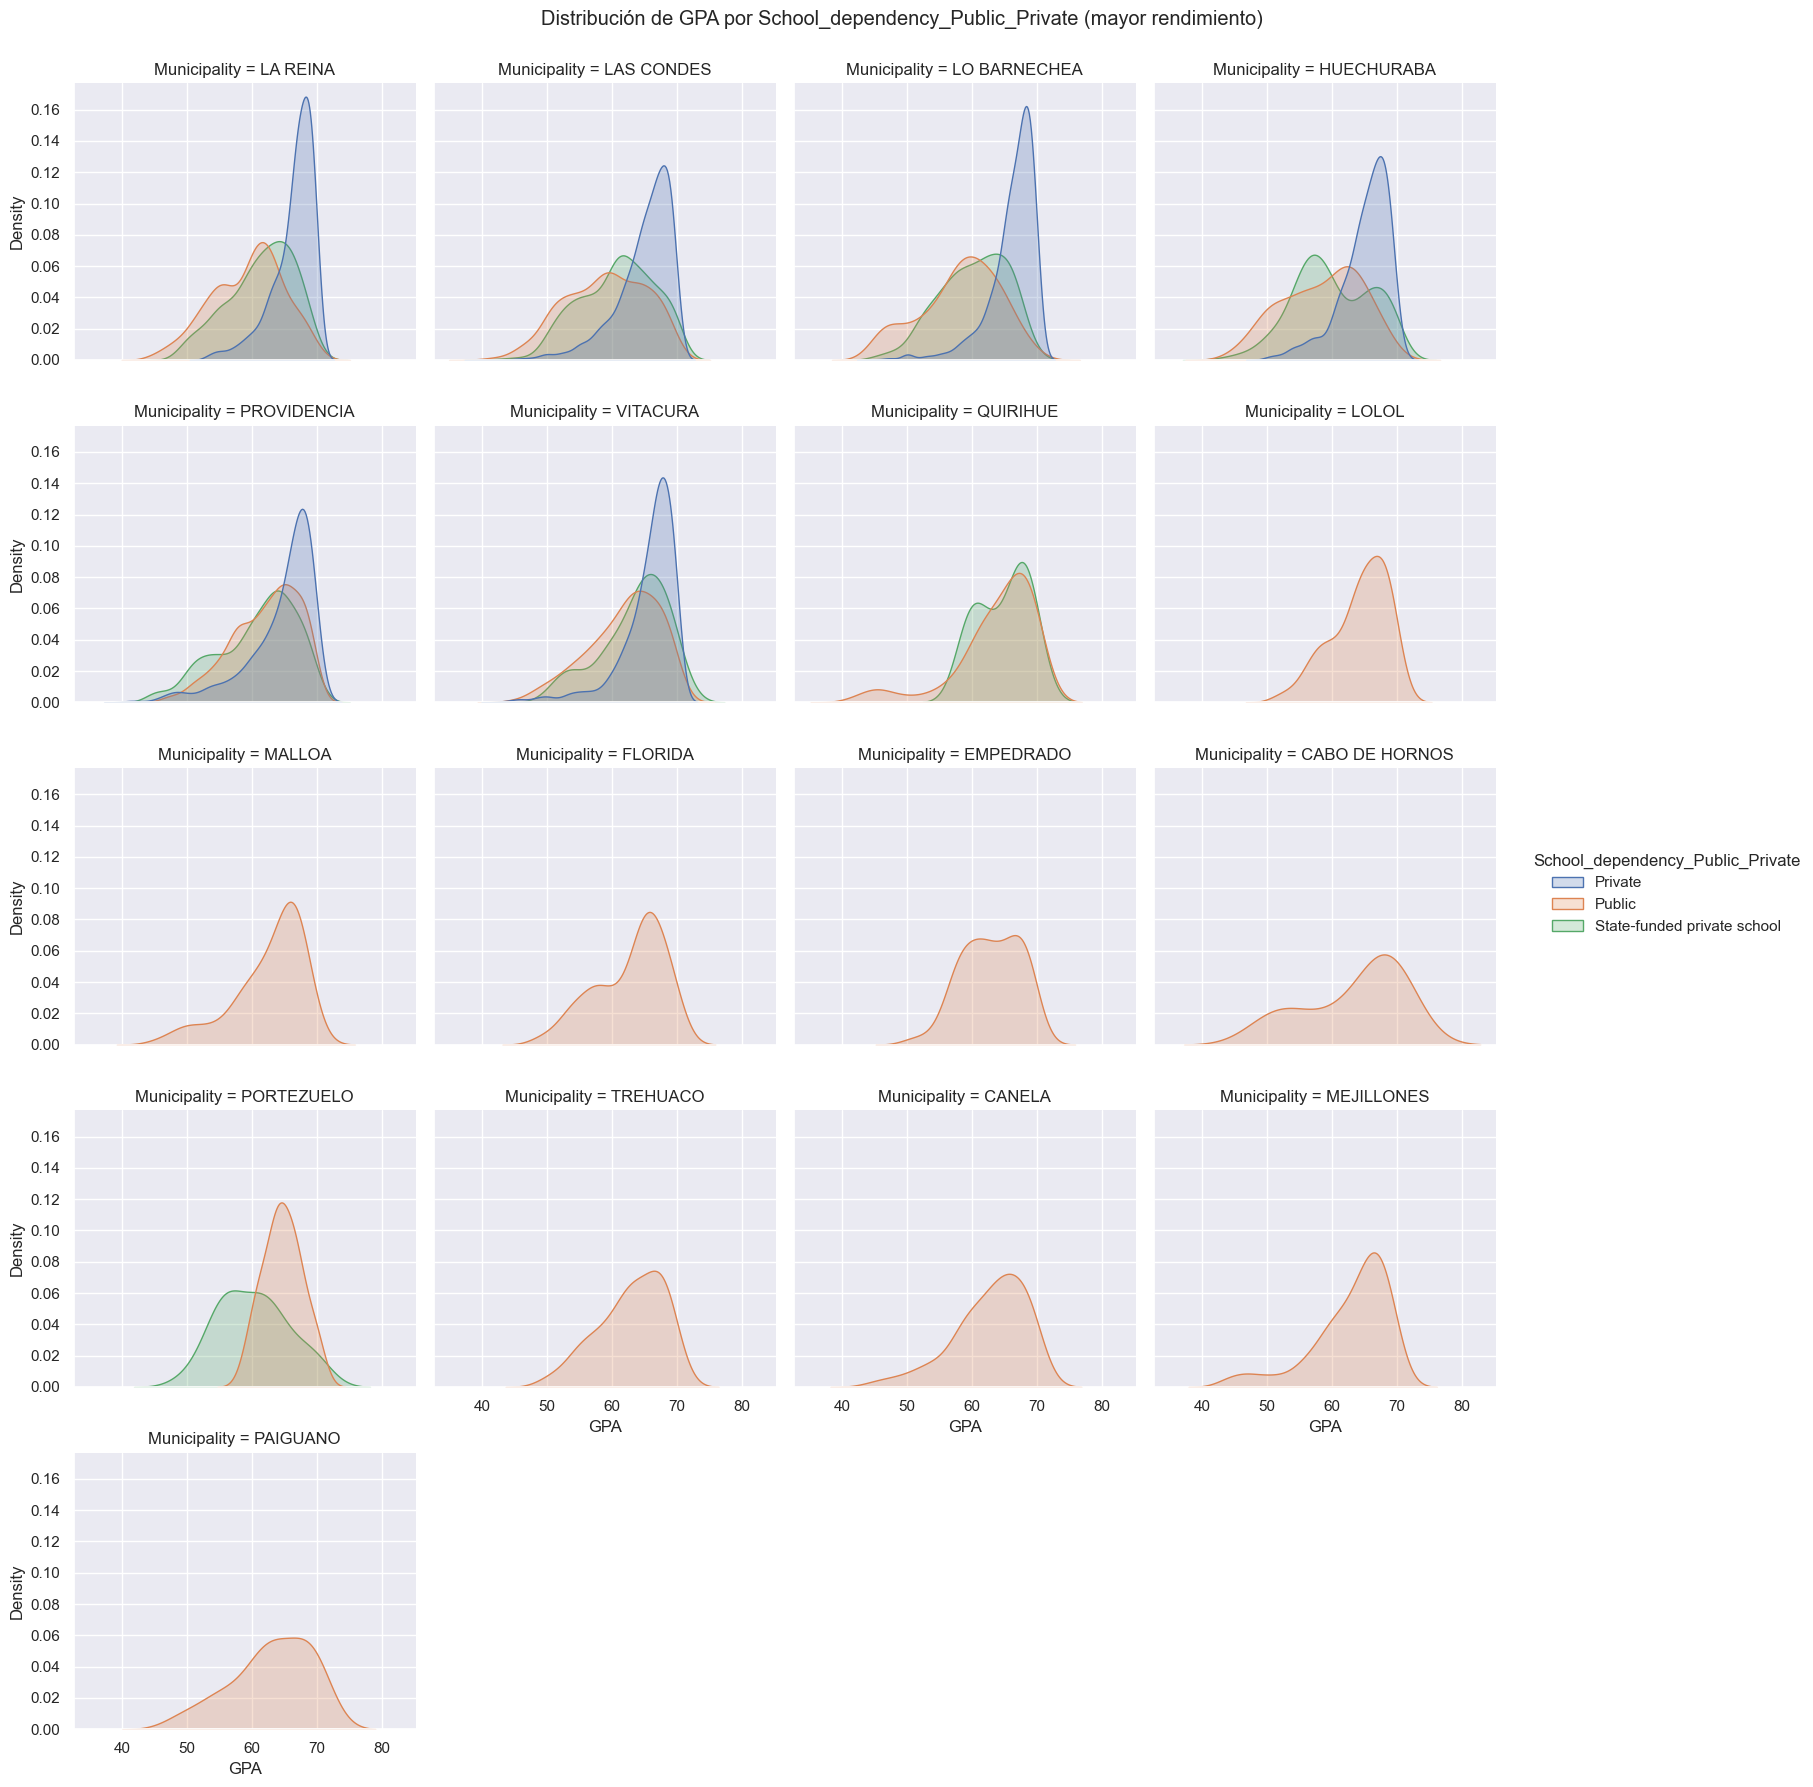

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Lista de las nuevas comunas específicas (Top rendimiento)
comunas_lista = [
    'VITACURA', 'LO BARNECHEA', 'LOLOL', 'QUIRIHUE', 'LA REINA', 'CABO DE HORNOS',
    'LAS CONDES', 'PAIGUANO', 'TREHUACO', 'EMPEDRADO', 'MEJILLONES', 'PROVIDENCIA',
    'PORTEZUELO', 'FLORIDA', 'CANELA', 'MALLOA', 'HUECHURABA'
]

# 2. Filtrar el DataFrame
df_subconjunto = dfc[dfc['Municipality'].isin(comunas_lista)]

# 3. Graficar la distribución
g = sns.displot(
    data=df_subconjunto,
    x='GPA',
    hue='School_dependency_Public_Private',
    col='Municipality',
    col_wrap=4,              # Se acomodan en filas de 4
    kind='kde',
    common_norm=False,
    fill=True,
    height=3.5,
    aspect=1.1
)

g.fig.suptitle('Distribución de GPA por School_dependency_Public_Private (mayor rendimiento)', y=1.02)
plt.show()

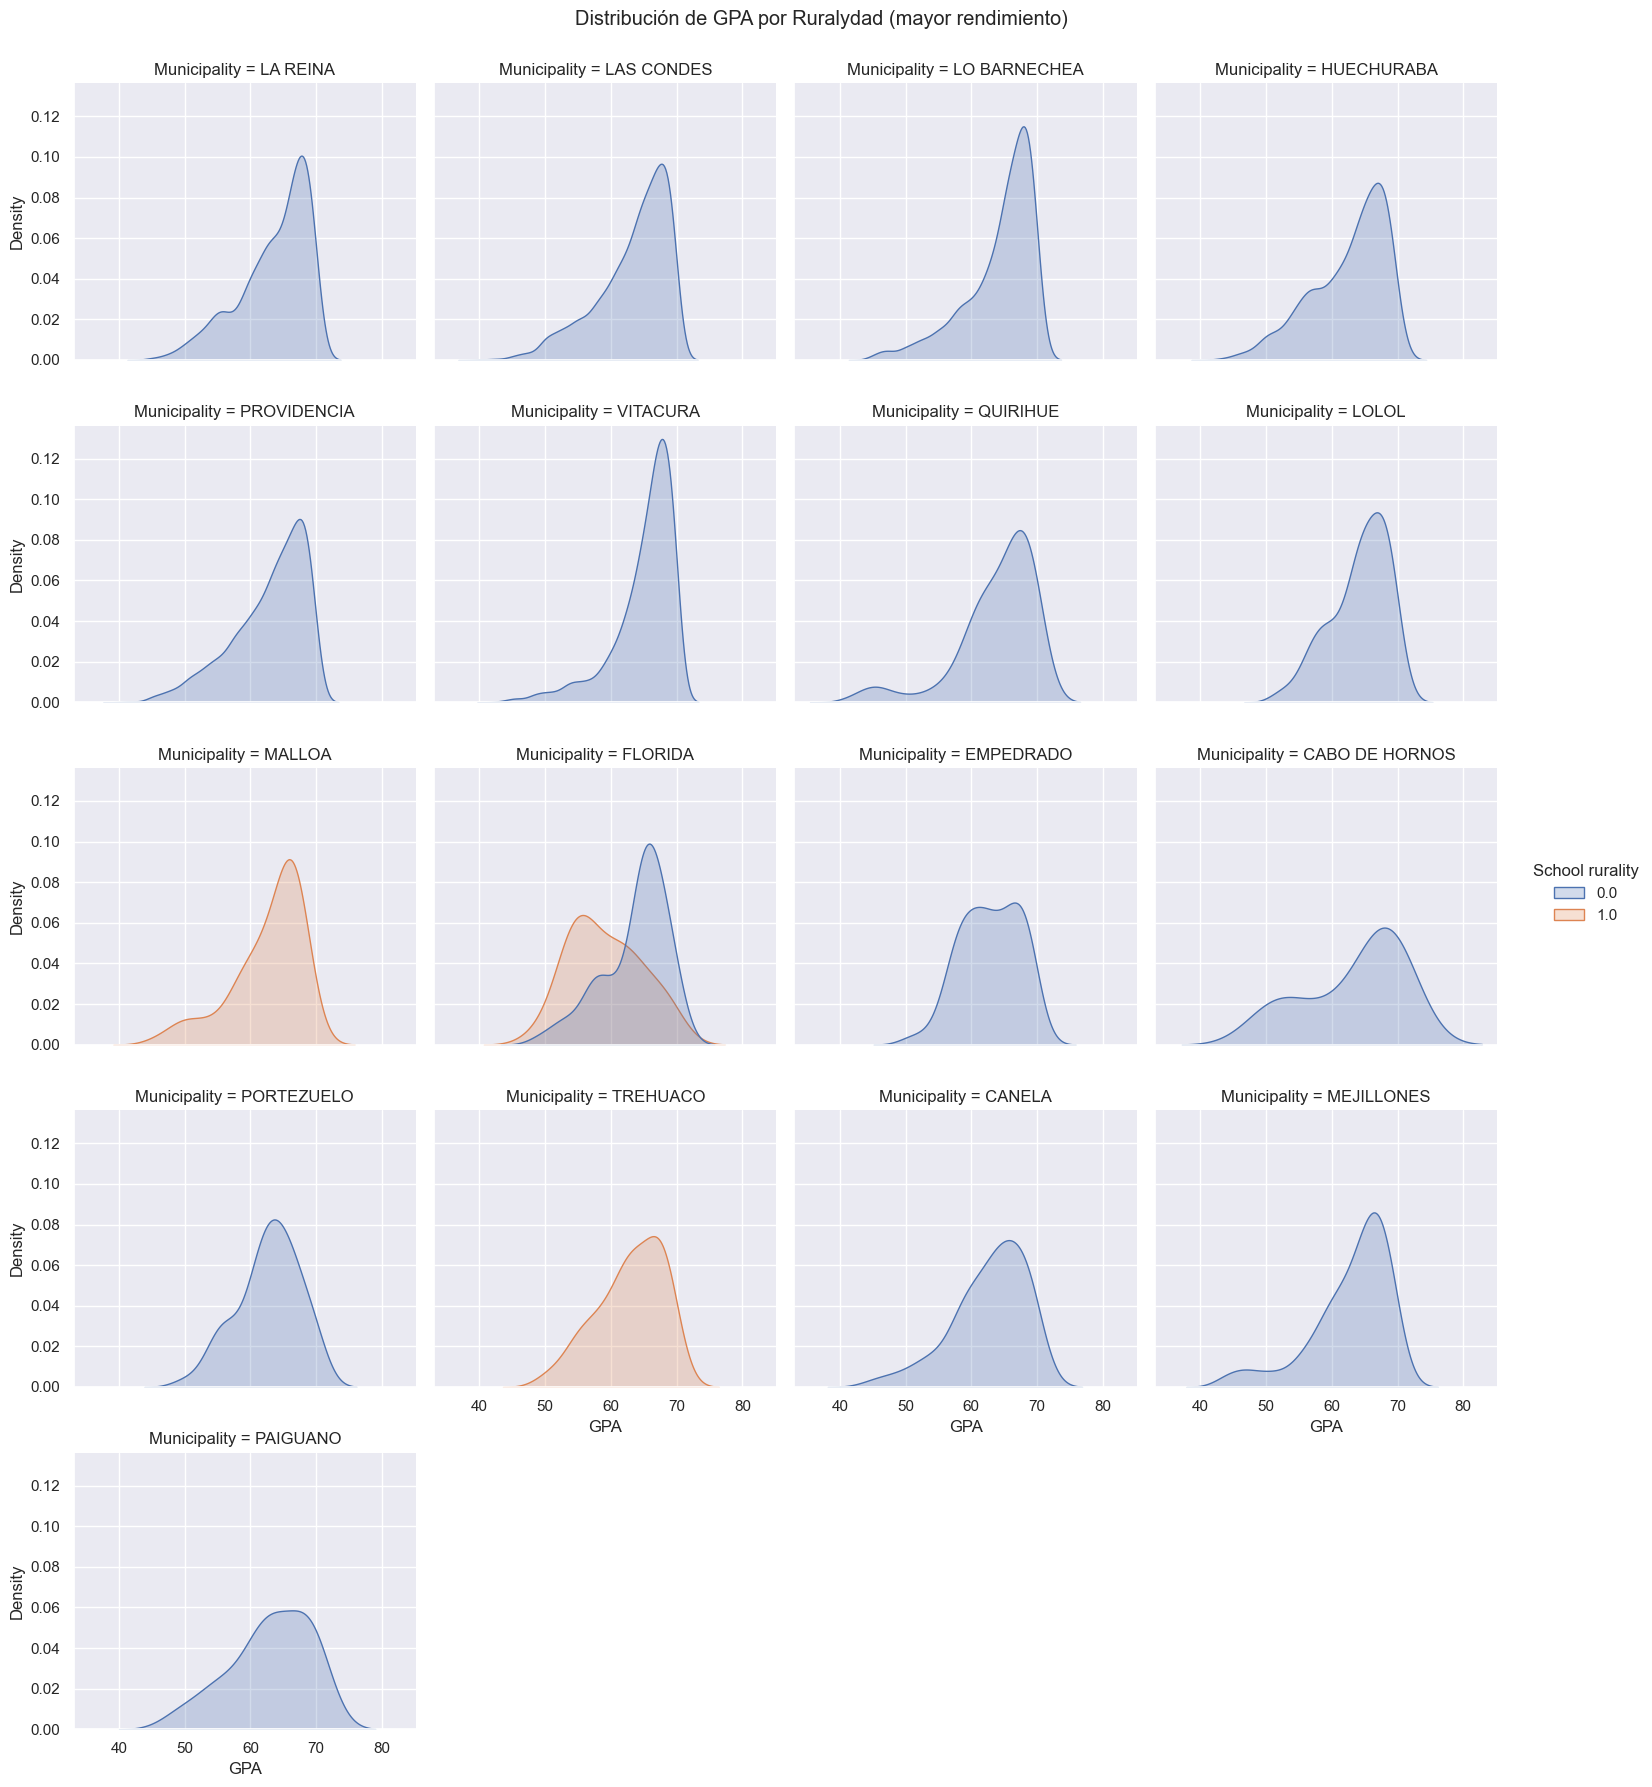

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Lista de las nuevas comunas específicas (Top rendimiento)
comunas_lista = [
    'VITACURA', 'LO BARNECHEA', 'LOLOL', 'QUIRIHUE', 'LA REINA', 'CABO DE HORNOS',
    'LAS CONDES', 'PAIGUANO', 'TREHUACO', 'EMPEDRADO', 'MEJILLONES', 'PROVIDENCIA',
    'PORTEZUELO', 'FLORIDA', 'CANELA', 'MALLOA', 'HUECHURABA'
]

# 2. Filtrar el DataFrame
df_subconjunto = dfc[dfc['Municipality'].isin(comunas_lista)]

# 3. Graficar la distribución
g = sns.displot(
    data=df_subconjunto,
    x='GPA',
    hue='School rurality',
    col='Municipality',
    col_wrap=4,              # Se acomodan en filas de 4
    kind='kde',
    common_norm=False,
    fill=True,
    height=3.5,
    aspect=1.1
)

g.fig.suptitle('Distribución de GPA por Ruralydad (mayor rendimiento)', y=1.02)
plt.show()

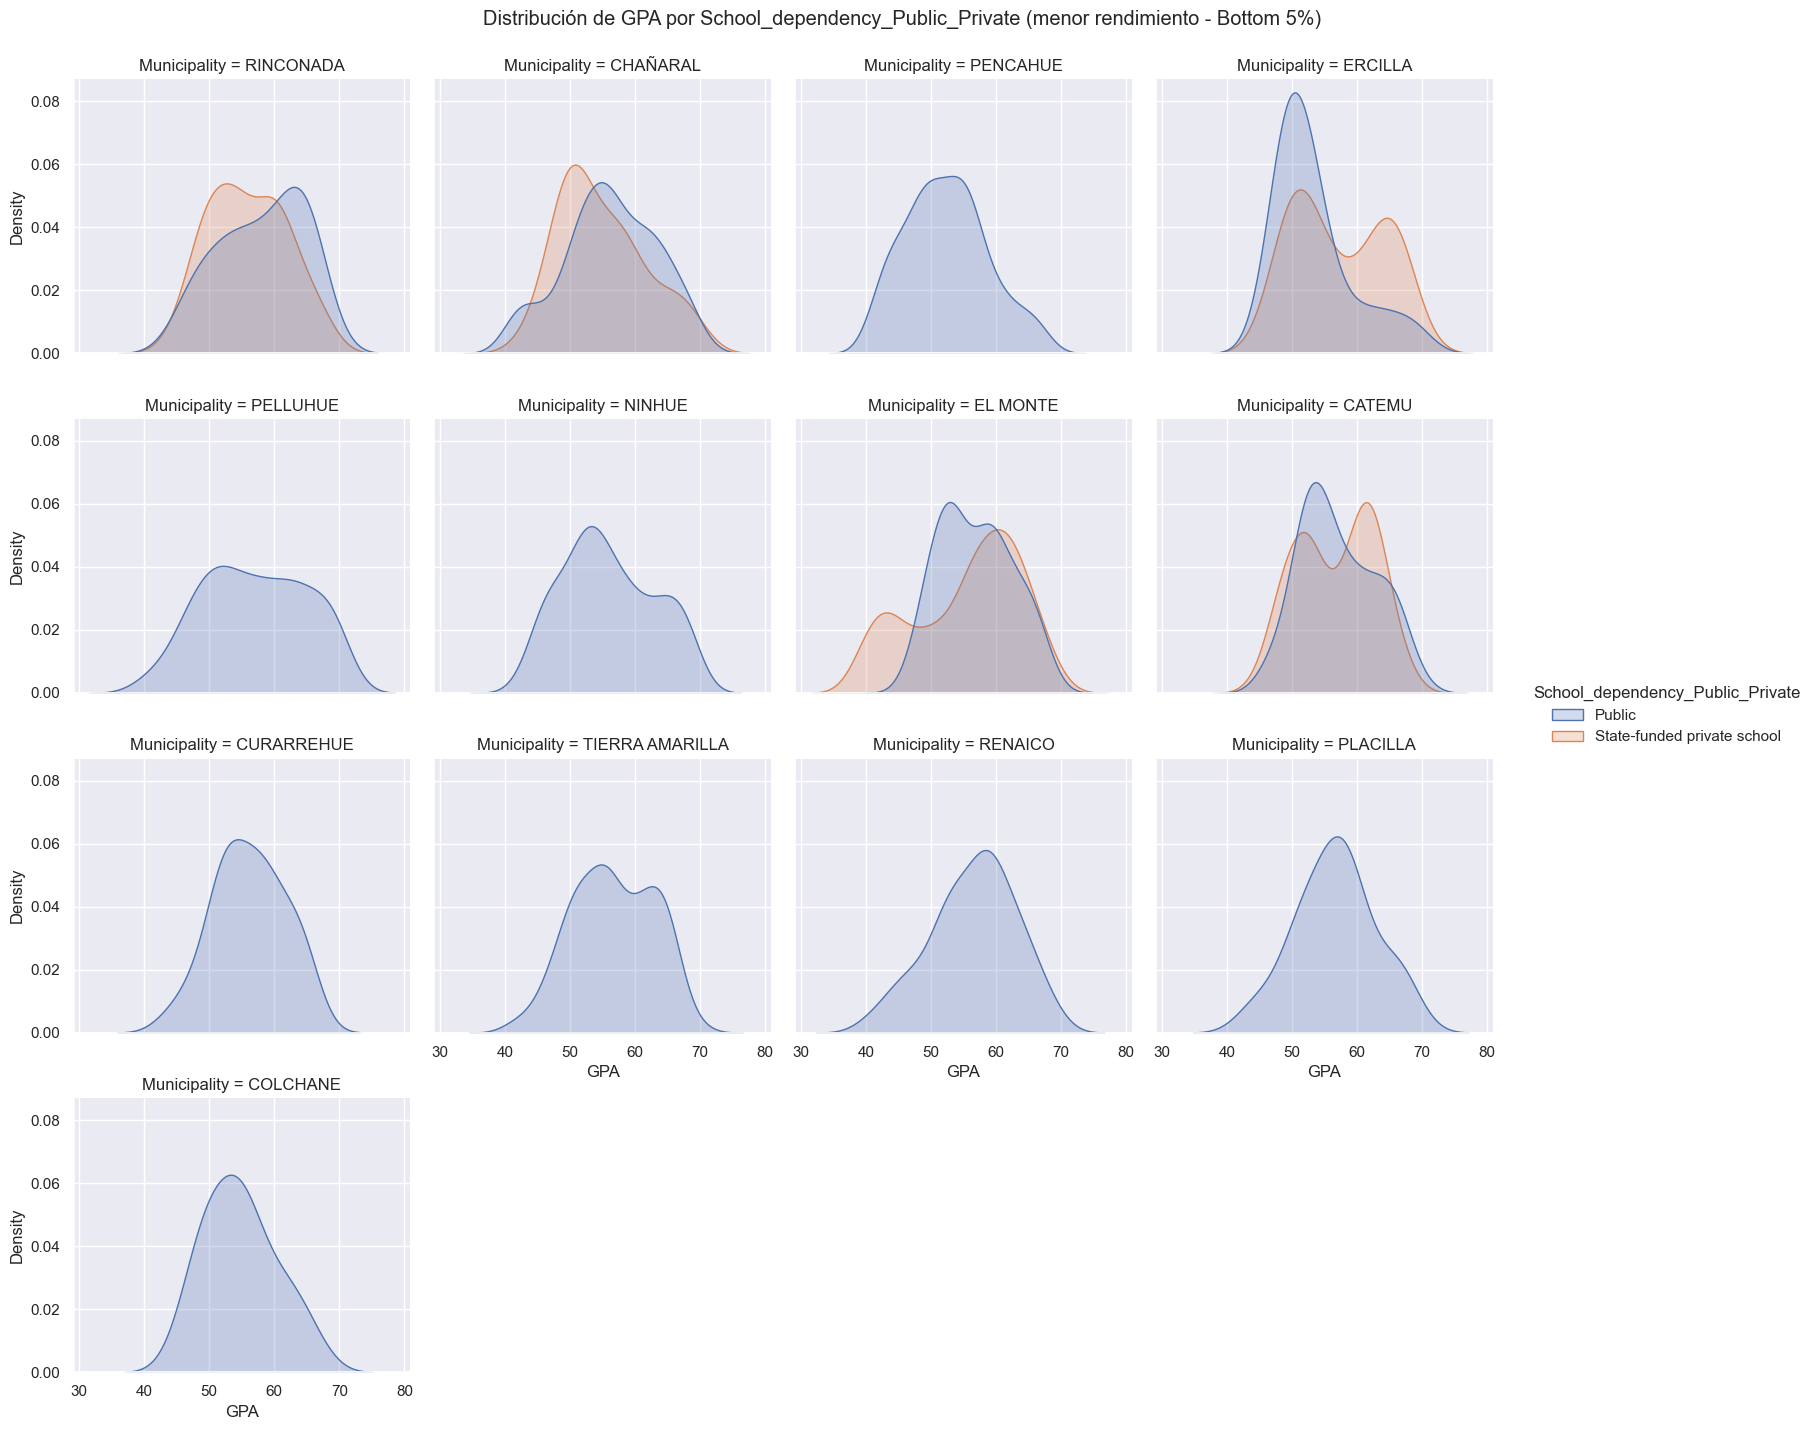

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Lista de las comunas del Bottom 5% (menor rendimiento)
comunas_lista = [
    'PENCAHUE', 'COLCHANE', 'ERCILLA', 'EL MONTE', 'NINHUE', 'CHAÑARAL',
    'CURARREHUE', 'RENAICO', 'TIERRA AMARILLA', 'PLACILLA', 'RINCONADA',
    'CATEMU', 'PELLUHUE'
]

# 2. Filtrar el DataFrame
df_subconjunto = dfc[dfc['Municipality'].isin(comunas_lista)]

# 3. Graficar la distribución
g = sns.displot(
    data=df_subconjunto,
    x='GPA',
    hue='School_dependency_Public_Private',
    col='Municipality',
    col_wrap=4,              # Acomoda 4 gráficos por fila
    kind='kde',
    common_norm=False,
    fill=True,
    height=3.5,
    aspect=1.1
)

g.fig.suptitle('Distribución de GPA por School_dependency_Public_Private (menor rendimiento - Bottom 5%)', y=1.02)
plt.show()

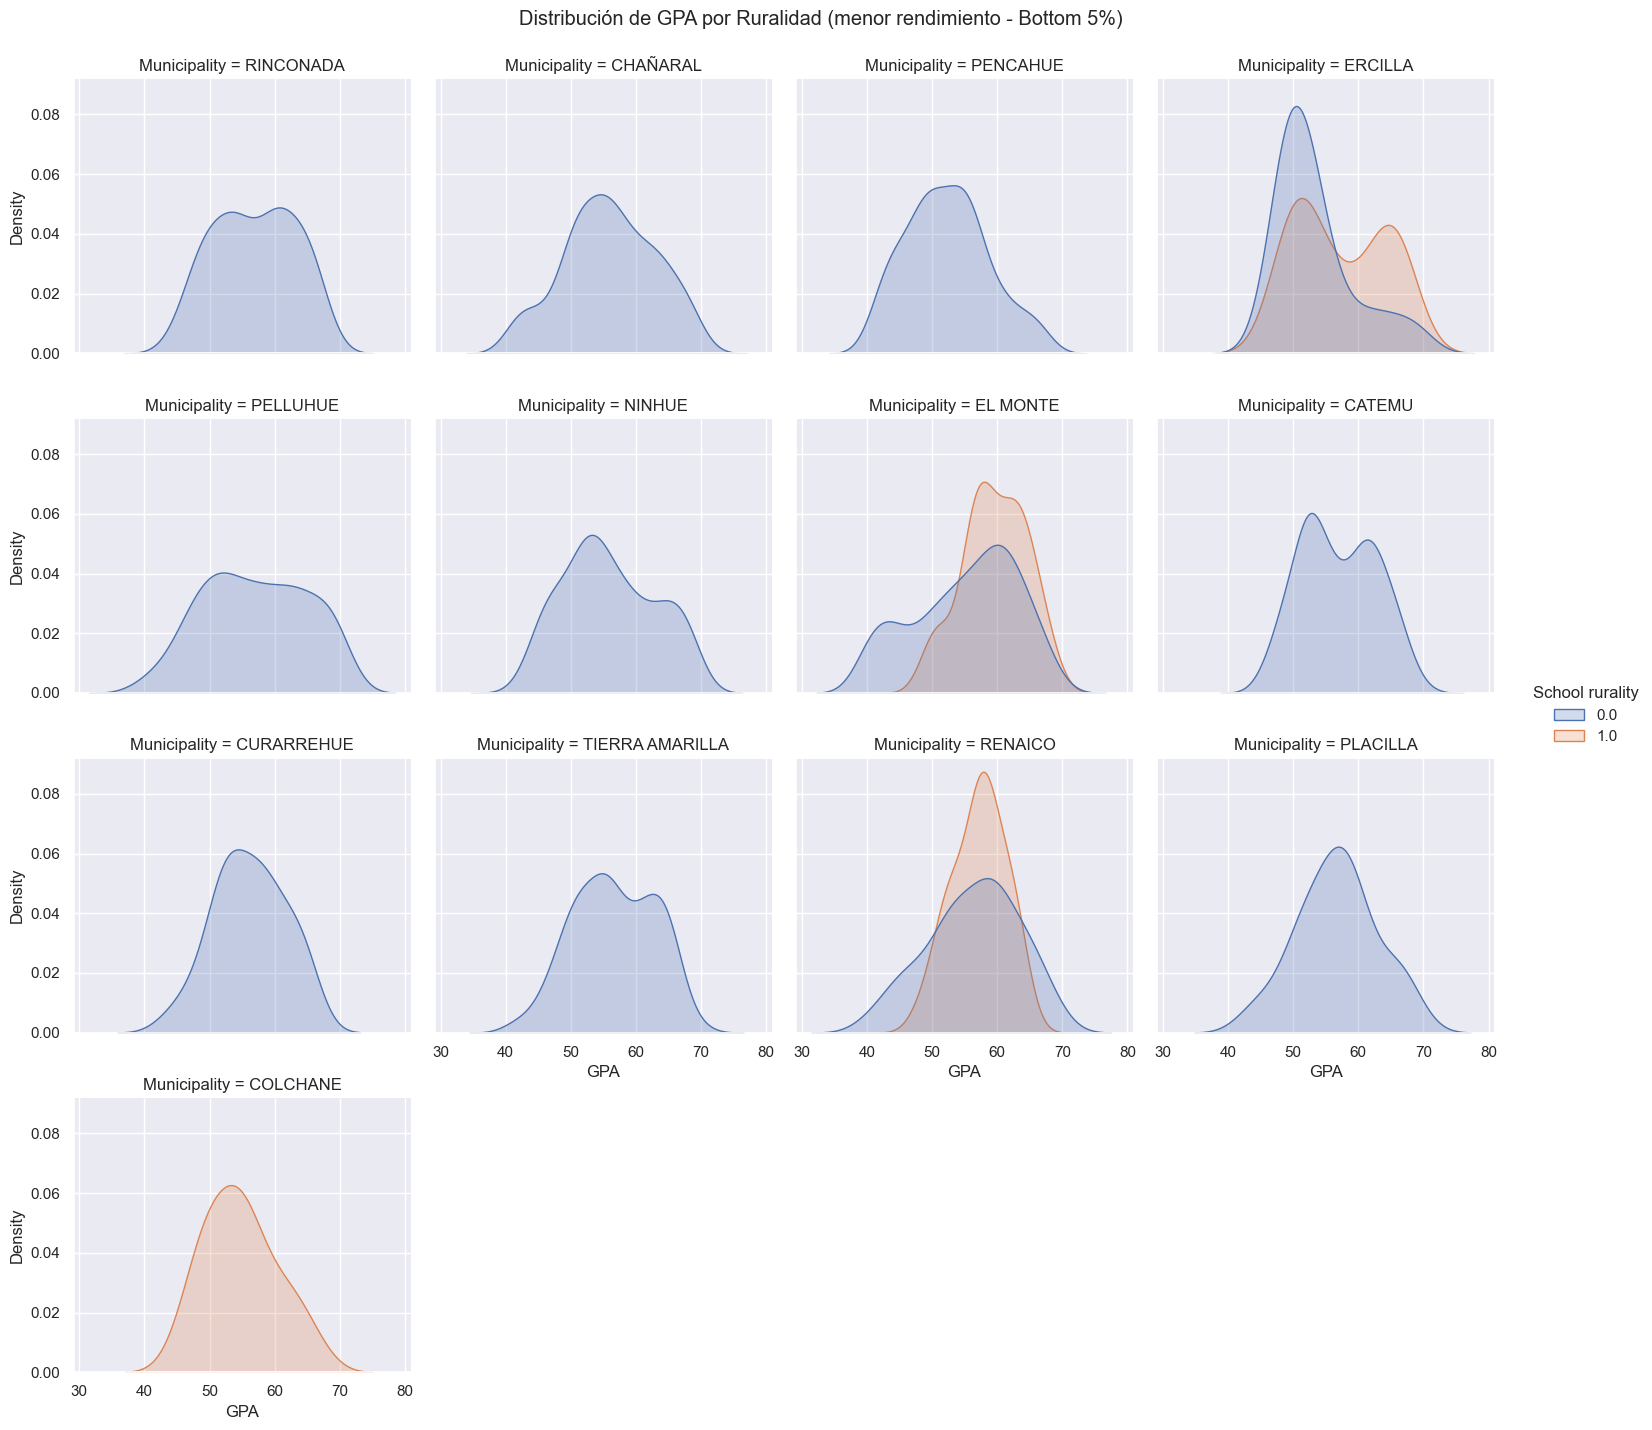

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Lista de las comunas del Bottom 5% (menor rendimiento)
comunas_lista = [
    'PENCAHUE', 'COLCHANE', 'ERCILLA', 'EL MONTE', 'NINHUE', 'CHAÑARAL',
    'CURARREHUE', 'RENAICO', 'TIERRA AMARILLA', 'PLACILLA', 'RINCONADA',
    'CATEMU', 'PELLUHUE'
]

# 2. Filtrar el DataFrame
df_subconjunto = dfc[dfc['Municipality'].isin(comunas_lista)]

# 3. Graficar la distribución
g = sns.displot(
    data=df_subconjunto,
    x='GPA',
    hue='School rurality',
    col='Municipality',
    col_wrap=4,              # Acomoda 4 gráficos por fila
    kind='kde',
    common_norm=False,
    fill=True,
    height=3.5,
    aspect=1.1
)

g.fig.suptitle('Distribución de GPA por Ruralidad (menor rendimiento - Bottom 5%)', y=1.02)
plt.show()

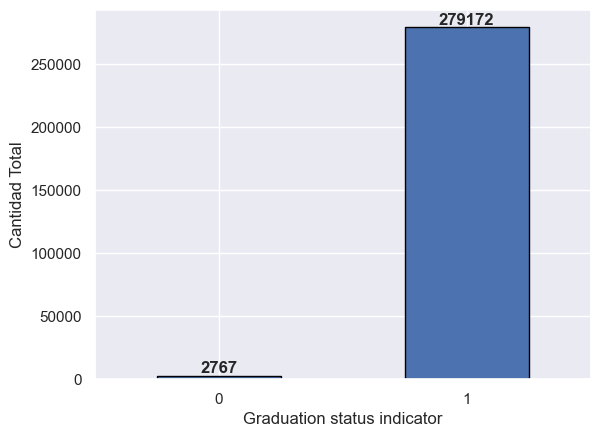

In [70]:
ax = ( dfc["Graduation status indicator"] .value_counts().sort_index().plot(kind="bar", edgecolor="black", rot=0))ax.bar_label(ax.containers[0], fontweight="bold")plt.ylabel("Cantidad Total")
plt.show()

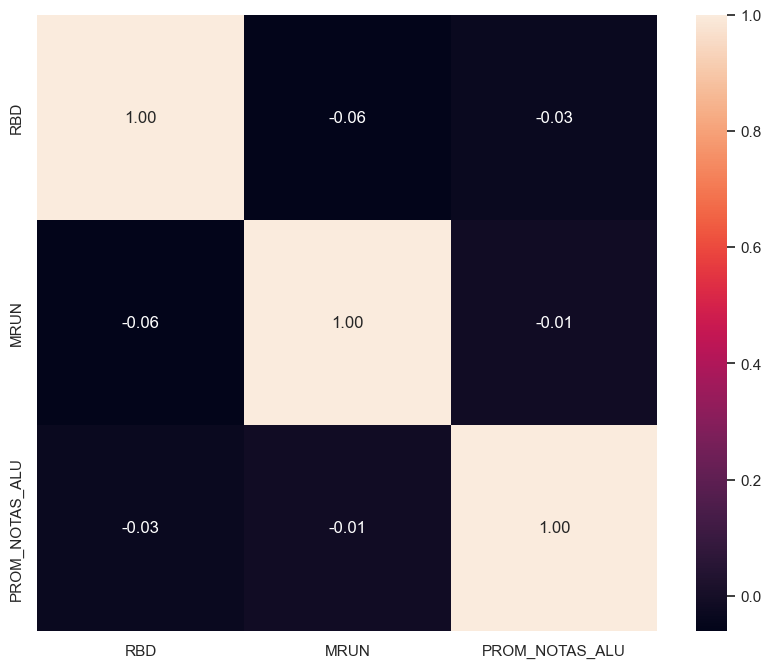

In [96]:
NumericalFeatures=df.select_dtypes(include=['float64',"int64"])
Correlation_matrix=NumericalFeatures.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(Correlation_matrix, annot=True, fmt='.2f',annot_kws={"size": 12},)
plt.show()

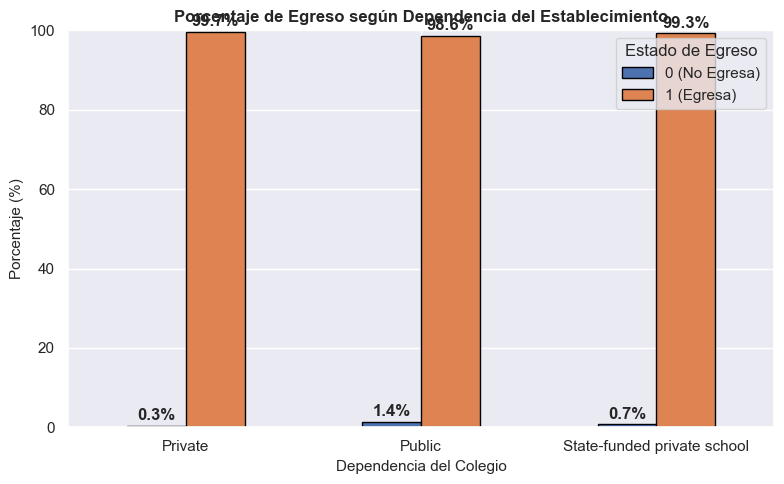

In [72]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Tabla cruzada normalizada por fila (calcula el porcentaje dentro de cada tipo de colegio)
cross_tab_pct = (
    pd.crosstab(
        dfc["School_dependency_Public_Private"],
        dfc["Graduation status indicator"],
        normalize="index",
    )
    * 100
)

# 2. Graficar en porcentaje
ax = cross_tab_pct.plot(kind="bar", edgecolor="black", rot=0, figsize=(8, 5))

# 3. Formatear la etiqueta de cada barra con el símbolo %
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontweight="bold", padding=2)

plt.title(
    "Porcentaje de Egreso según Dependencia del Establecimiento",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Dependencia del Colegio", fontsize=11)
plt.ylabel("Porcentaje (%)", fontsize=11)
plt.ylim(0, 100)  # Fija el eje Y hasta el 100%
plt.legend(["0 (No Egresa)", "1 (Egresa)"], title="Estado de Egreso")
plt.tight_layout()
plt.show()

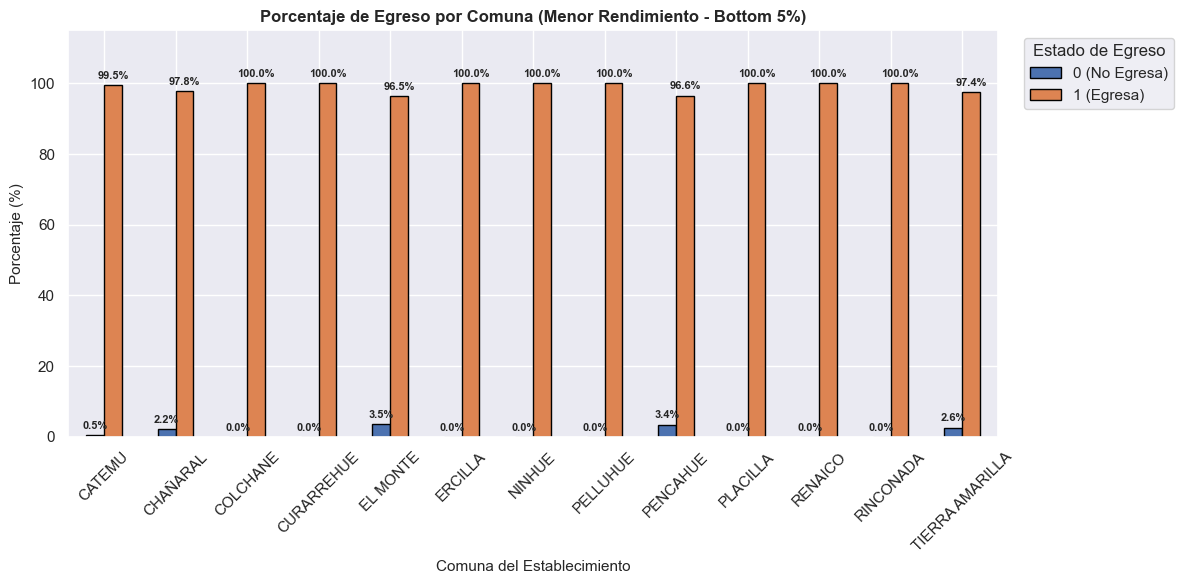

In [74]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Lista de comunas seleccionadas (Bottom 5%)
comunas_lista = [
    "PENCAHUE",
    "COLCHANE",
    "ERCILLA",
    "EL MONTE",
    "NINHUE",
    "CHAÑARAL",
    "CURARREHUE",
    "RENAICO",
    "TIERRA AMARILLA",
    "PLACILLA",
    "RINCONADA",
    "CATEMU",
    "PELLUHUE",
]

# 2. Filtrar DataFrame
df_subconjunto = dfc[dfc["Municipality"].isin(comunas_lista)]

# 3. Calcular tabla cruzada en porcentaje dentro de cada comuna
cross_tab_bottom = (
    pd.crosstab(
        df_subconjunto["Municipality"],
        df_subconjunto["Graduation status indicator"],
        normalize="index",
    )
    * 100
)

# 4. Graficar
ax = cross_tab_bottom.plot(kind="bar", edgecolor="black", rot=45, figsize=(12, 6))

# Agregar etiquetas de % arriba de cada barra
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontweight="bold", padding=3, fontsize=8)

plt.title(
    "Porcentaje de Egreso por Comuna (Menor Rendimiento - Bottom 5%)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Comuna del Establecimiento", fontsize=11)
plt.ylabel("Porcentaje (%)", fontsize=11)
plt.ylim(0, 115)
plt.legend(
    ["0 (No Egresa)", "1 (Egresa)"],
    title="Estado de Egreso",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
plt.tight_layout()
plt.show()


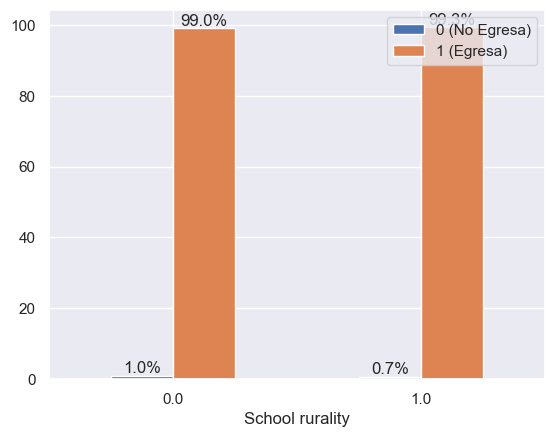

In [95]:
ct = pd.crosstab(dfc["School rurality"], dfc["Graduation status indicator"], normalize="index") * 100
ax = ct.plot(kind="bar", rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%")
plt.legend(["0 (No Egresa)", "1 (Egresa)"])
plt.show()

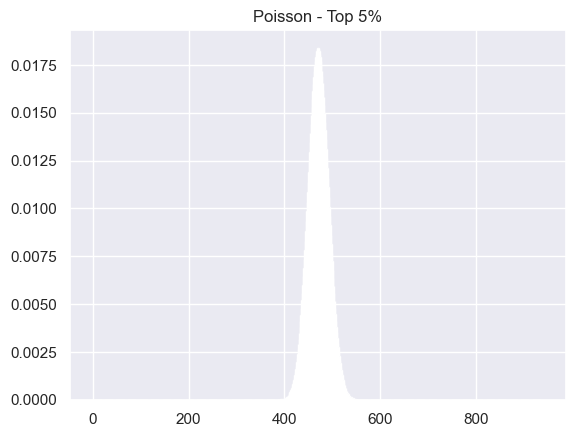

In [94]:
dfc_rural = dfc[dfc["School rurality"] == 1]
n_rural = len(dfc_rural)
lambda_top5 = n_rural * 0.05

x1 = range(0, max(10, int(lambda_top5 * 2)))
plt.bar(x1, poisson.pmf(x1, lambda_top5))
plt.title("Poisson - Top 5%")
plt.show()


In [88]:
dfc_rural = dfc[dfc["School rurality"] == 1]
n_rural = len(dfc_rural)
k_no_egresa = (dfc_rural["Graduation status indicator"] == 0).sum()
lambda_no_egreso = n_rural * (k_no_egresa / n_rural) if n_rural > 0 else 0

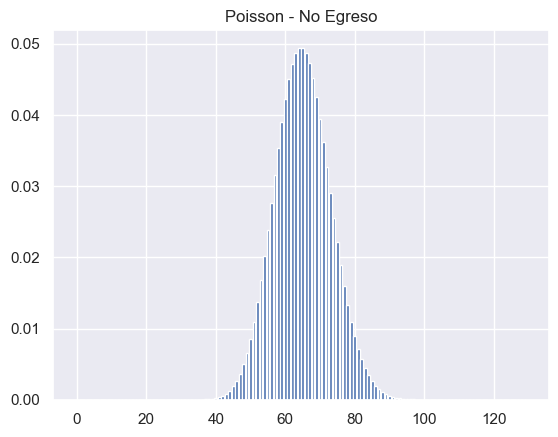

In [89]:
x2 = range(0, max(10, int(lambda_no_egreso * 2)))
plt.bar(x2, poisson.pmf(x2, lambda_no_egreso))
plt.title("Poisson - No Egreso")
plt.show()